<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<h1><center><font size=10>Artificial Intelligence and Machine Learning</center></font></h1>



<center> <font size=6> Project Python Foundations: FoodHub Data Analysis

<center><img src="https://www.netsolutions.com/wp-content/uploads/2022/10/essential-features-of-building-an-on-demand-food-ordering-app.jpg" width="720"></center>


### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [11]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [12]:
df = pd.read_csv('/home/zachary-steuer/Desktop/Foodhub/foodhub_order.csv')

In [13]:
# Displays first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [14]:
# Using the shape() attribute on the DataFrame, we can see that there are 1898 rows and 9 columns
df.shape

(1898, 9)

#### Observations:
There are 1898 rows and 9 columns


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [15]:
# info() function lists the columns/index numbers along with the non-Na values and datatype
column_type = df.info()
print(column_type)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB
None


#### Observations:
order_id, customer_id, food_preparation_time, and delivery_time are int64

restaurant_name, cuisine_type, day_of_the_week, and rating are objects (I changed rating to be a integer later on. This was done so that I could do mathmatical calculations on the ratings. This was not possible as a string.

cost_of_the_order is a float64

### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

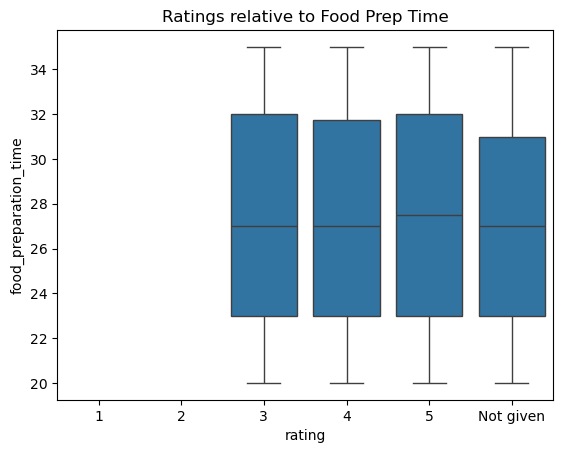

In [16]:
# plot the "not given values" relative to food prep time vs all other ratings with numerical values and their delivery time
sns.boxplot(data=df, x=df['rating'], y=df['food_preparation_time'], order=[1,2,3,4,5,'Not given'])
plt.title('Ratings relative to Food Prep Time');

In [17]:
# Loop through all columns and sum up all null values
for col in df.columns:
  print(col, 'Null Values:',df[col].isnull().sum())

# Ratings should be a int64 but is an object type, This is because one of the data inputs is'Ratings Not given'(object). Show how many 'Not Given' values are in the rating column
not_given = 0

for value in df['rating']:
  if value == 'Not given':
    not_given += 1
print('\n','number of "Not given" values in ratings column is:', not_given)

question_5_answer = not_given



order_id Null Values: 0
customer_id Null Values: 0
restaurant_name Null Values: 0
cuisine_type Null Values: 0
cost_of_the_order Null Values: 0
day_of_the_week Null Values: 0
rating Null Values: 0
food_preparation_time Null Values: 0
delivery_time Null Values: 0

 number of "Not given" values in ratings column is: 736


In [18]:
# change all 'Not given' values in rating column to NAN
df['rating'] = df['rating'].replace('Not given', np.nan)


In [19]:
# change all values in ratings column to int64
df['rating'] = df['rating'].astype(float)
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,NaN,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,NaN,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5.0,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3.0,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4.0,25,24


In [20]:
#Ensures all values in ratings column are numbers and are accounted for.
total_count_reviews = 0
for value in df['rating']:
  if np.isnan(value):
    total_count_reviews += 1
  elif value == 3:
    total_count_reviews += 1
  elif value == 4:
   total_count_reviews += 1
  elif value == 5:
    total_count_reviews += 1

print(total_count_reviews)


1898


In [21]:
#convert all NaN values to the mean of available rating data.
data = df['rating']
data.head()

#determine number of entered values
rating_mean_count = 0
for i in data:
  if i == 1:
    rating_mean_count += 1
  elif i == 2:
    rating_mean_count += 1
  elif i == 3:
    rating_mean_count += 1
  elif i == 4:
    rating_mean_count += 1
  elif i == 5:
    rating_mean_count += 1


#sum of entered values in rating data
rating_mean_sum = 0
for i in data:
  if i == 1:
    rating_mean_sum += 1
  elif i ==2:
    rating_mean_sum +=2
  elif i ==3:
    rating_mean_sum +=3
  elif i ==4:
    rating_mean_sum +=4
  elif i ==5:
    rating_mean_sum +=5

rating_mean_value = rating_mean_sum / rating_mean_count
print(rating_mean_value)
#mean value of available data in ratings column
rating_mean_value = round(rating_mean_value)



4.344234079173838


In [22]:
#replace all nan values in ratings column with the mean value of available entries
df['rating'] = df['rating'].replace(np.nan, rating_mean_value)

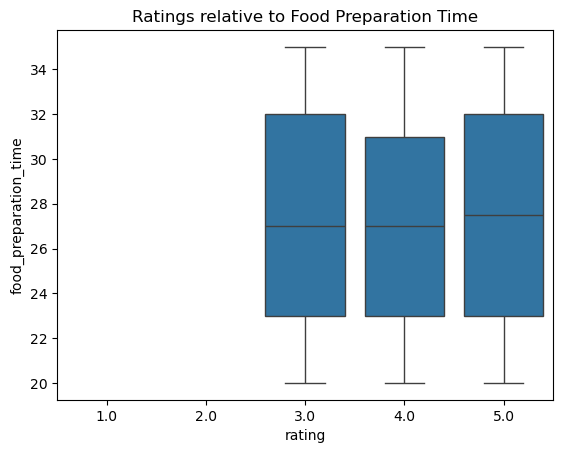

In [23]:
# ratings boxplot relative to delivery time, this imputates the NaN values with the mean of available data.
sns.boxplot(data=df, x=df['rating'],y=df['food_preparation_time'],order=[1.0,2.0,3.0,4.0,5.0])
plt.title('Ratings relative to Food Preparation Time');



#### Observations:
My initial findings showed that the only missing values in the dataset were in the ratings column. Analysis showed that 735 out of 1898 rows were missing ratings. I believe this is due to users choosing to not leave a rating when going through Foodhub.

To understand the data further, I created a boxplot comparing ratings to time it took to prepare the food. My hypothesis was that if I could not find a correlation between food prep time and ratings, I could use the mean to impute the values 'Not given'.

If the 'Not given' data didn't correlate, high or poor service might scew their opinions either toward 1 or 5 star ratings.

My observation was there is little to no correlation between not giving a rating and prep time. Because of this I used the mean to impute the 'Not given' values. The rounded mean was a rating of 4.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [24]:
#minimum time it takes to prepare an order
prep_min = df['food_preparation_time'].min()
print("minimum amount of time to prep food:",prep_min)

minimum amount of time to prep food: 20


In [25]:
#average time it takes to prepare an order
prep_average = df['food_preparation_time'].mean()
print("average amount of time to prep food:",prep_average)

average amount of time to prep food: 27.371970495258168


In [26]:
#maximum time it takes to prepare an order
prep_max = df['food_preparation_time'].max()
print("mmaximum amount of time to prep food:", prep_max)

mmaximum amount of time to prep food: 35


#### Observations:
The minimum amount of time to prep food is 20 minutes
the average amount of time to prep food is 27.37 minutes
the maximum amount of time to prep food is 35 minutes

### **Question 5:** How many orders are not rated? [1 mark]

In [27]:
#Answer was calculated in question 2 code. Named the variable question_5_answer
print(question_5_answer)

736


#### Observations:
There were 736 orders that were not rated before I imputed the dataframe.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

In [28]:
# resturant_name
restaurant_count = df['restaurant_name'].value_counts().head(60)

In [29]:
#Take IQR code and make it into a function to reuse
def IQR(column):

  # Calculate quantiles on the restaurant_count
  Q1 = column.quantile(0.25)
  Q3 = column.quantile(0.75)

  IQR = Q3-Q1

  # lower_bound = Q1 - 1.5 * IQR (Not Needed)
  upper_bound = Q3 + 1.5 * IQR
  lower_bound = Q1 - 1.5 * IQR

  print('IQR:', IQR)
  print('Q1:', Q1)
  print('Q3:', Q3)
  print('upper bound:', upper_bound)
  print('lower bound:', lower_bound)






In [30]:
#Take IQR code and make it into a function for restaurants


 ###(Fix to a bug want to clean up code later)


  # Get the count of orders for each restaurant
restaurant_count = df['restaurant_name'].value_counts()

  # Calculate quantiles on the restaurant_count
Q1_1 = restaurant_count.quantile(0.25)
Q3_1 = restaurant_count.quantile(0.75)

IQR_1 = Q3_1-Q1_1

  # lower_bound = Q1 - 1.5 * IQR (Not Needed)
upper_bound_1 = Q3_1 + 1.5 * IQR_1
lower_bound_1 = Q1_1 - 1.5 * IQR_1

print('IQR:',IQR_1)
print('Q1:', Q1_1)
print('Q3:', Q3_1)
print('upper bound:', upper_bound_1)
print('lower bound:', lower_bound_1)


frequent_restaurants = restaurant_count[restaurant_count > upper_bound_1]



IQR: 7.75
Q1: 1.0
Q3: 8.75
upper bound: 20.375
lower bound: -10.625


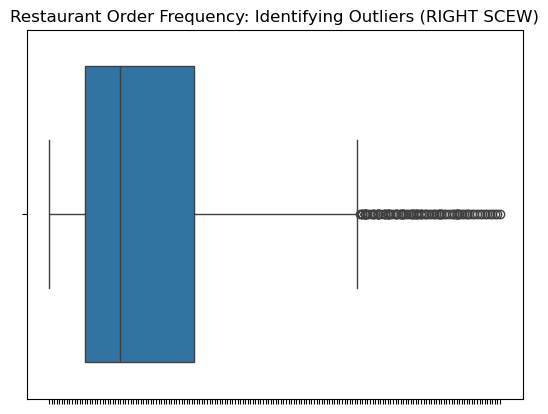

In [31]:
#boxplot of restaurant names and the count of how many times they occur in the data
box = sns.boxplot(data=df, x='restaurant_name');
box.set(xlabel=None)
box.set_xticklabels([])
plt.title('Restaurant Order Frequency: Identifying Outliers (RIGHT SCEW)');
plt.show()

In [32]:
IQR(df['restaurant_name'].value_counts())

IQR: 7.75
Q1: 1.0
Q3: 8.75
upper bound: 20.375
lower bound: -10.625


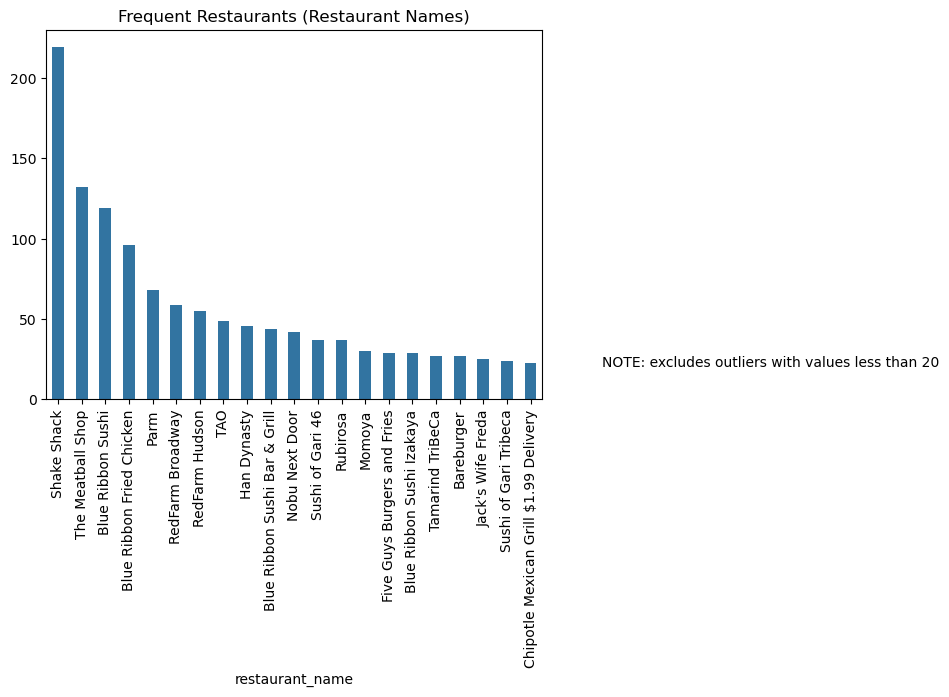

In [33]:
frequent_restaurants_bar_plot = sns.barplot(x=frequent_restaurants.index, y=frequent_restaurants.values, width =.5);
plt.xticks(rotation=90);
plt.annotate('NOTE: excludes outliers with values less than 20', xy=(1.12, 0.1), xycoords='axes fraction', ha='left', va='center');
plt.title('Frequent Restaurants (Restaurant Names)');

In [34]:
#cuisine_type ()
#count the number of occurances of each cuisine type
df['cuisine_type'].value_counts()

cuisine_type
American          584
Japanese          470
Italian           298
Chinese           215
Mexican            77
Indian             73
Middle Eastern     49
Mediterranean      46
Thai               19
French             18
Southern           17
Korean             13
Spanish            12
Vietnamese          7
Name: count, dtype: int64

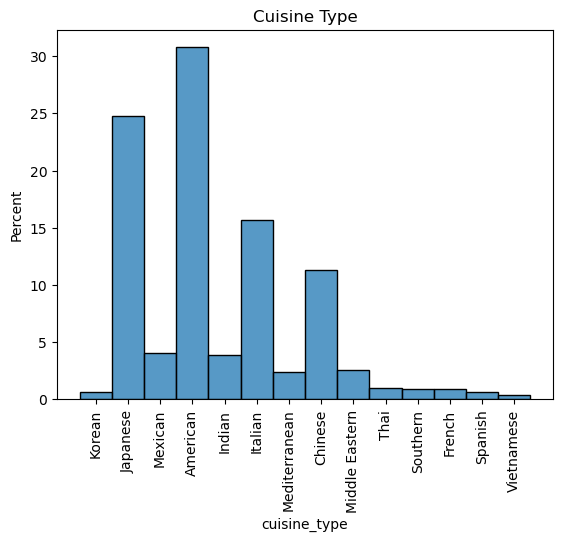

In [35]:
#cusine Type of all choices

sns.histplot(x=df['cuisine_type'], stat='percent')
plt.xticks(rotation=90)
plt.title('Cuisine Type')
plt.show()

In [36]:
#max cost of the order

df['cost_of_the_order'].max()


35.41

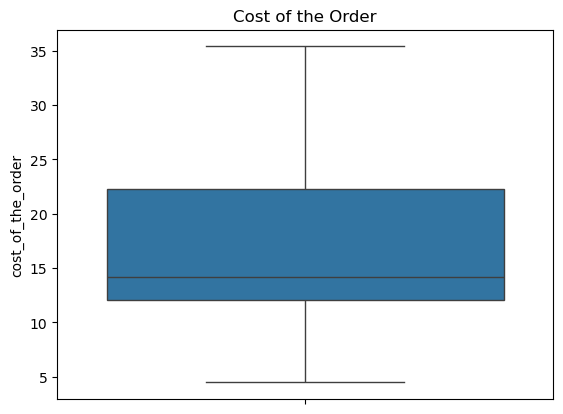

In [37]:
#Cost of the order Boxplot

sns.boxplot(df['cost_of_the_order'], showfliers=True);
plt.title('Cost of the Order');

In [38]:
IQR(df['cost_of_the_order'])

IQR: 10.2175
Q1: 12.08
Q3: 22.2975
upper bound: 37.62375
lower bound: -3.246249999999998


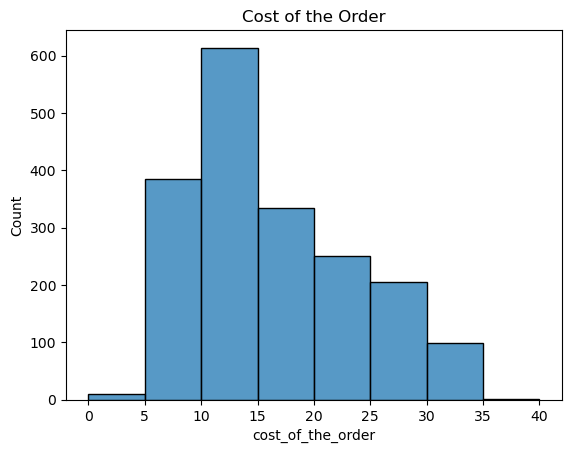

In [39]:
#cost of the order Histogram

sns.histplot(data=df['cost_of_the_order'],binwidth=5, binrange=[0,40]);
plt.title('Cost of the Order');

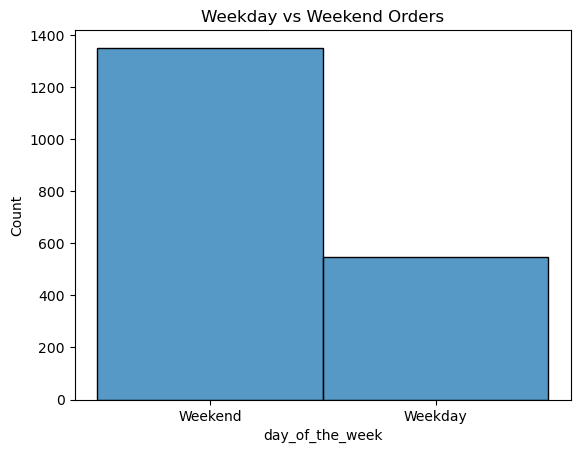

In [40]:
#day of the week Histogram

sns.histplot(data=df['day_of_the_week']);
plt.title('Weekday vs Weekend Orders');

In [41]:
#create function to find the percent value for day of the week
def dayoftheweek(column,day):
  percent_value = df[column].value_counts()[day] / df.shape[0] * 100
  print(day, ':', percent_value, '%' )

In [42]:
dayoftheweek('day_of_the_week', 'Weekend' )

Weekend : 71.18018967334035 %


In [43]:
dayoftheweek('day_of_the_week', "Weekday")

Weekday : 28.81981032665964 %


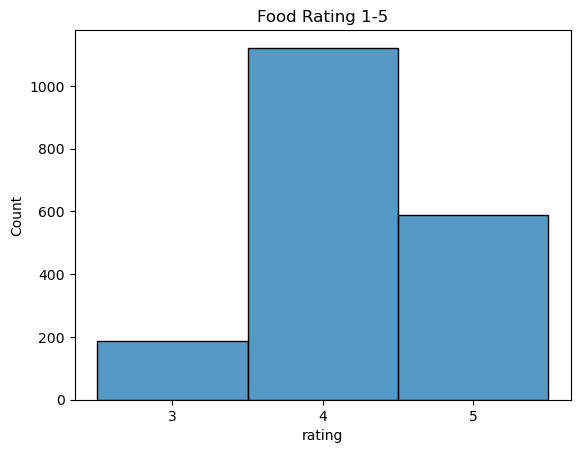

In [44]:
#Histogram of food ratings
df['rating'] = df['rating'].astype('category');
bins = [3.0,4.0,5.0];
sns.histplot(data=df['rating'], bins=bins );
plt.xticks([3,4,5]);
plt.title('Food Rating 1-5');


In [45]:
#create function to find the percent value for rating
def percent_rating(rating):
  percent_value = df['rating'].value_counts()[rating] / df.shape[0] * 100
  print('rating:',rating, ':', percent_value, '%' )

In [46]:
percent_rating(3.0)

rating: 3.0 : 9.905163329820864 %


In [47]:
percent_rating(4.0)

rating: 4.0 : 59.11485774499473 %


In [48]:
percent_rating(5.0)

rating: 5.0 : 30.979978925184405 %


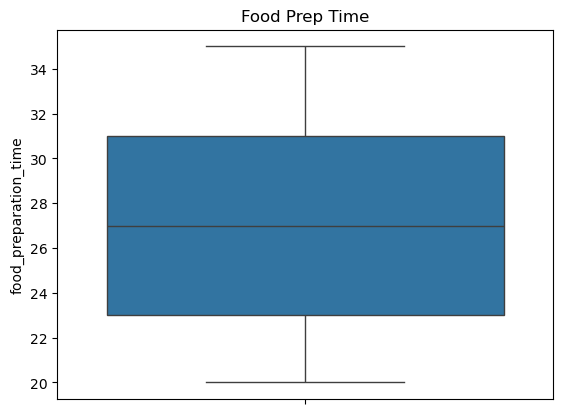

In [49]:
#boxplot of food prep time
sns.boxplot(data=df['food_preparation_time']);
plt.title('Food Prep Time');

In [50]:
IQR(df['food_preparation_time'])

IQR: 8.0
Q1: 23.0
Q3: 31.0
upper bound: 43.0
lower bound: 11.0


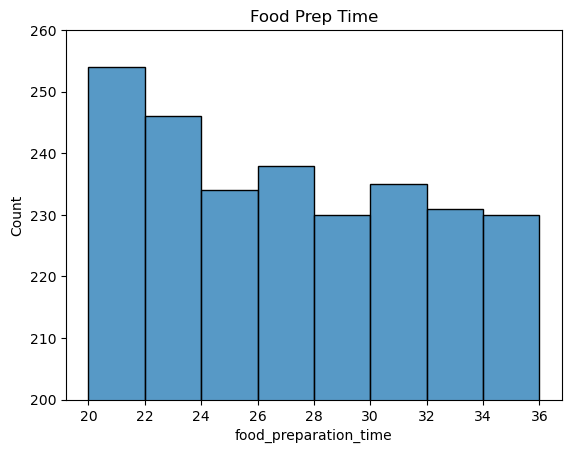

In [51]:
#Histogram of Food prep time
sns.histplot(data=df['food_preparation_time'], binrange=[20,36], binwidth=2, );
plt.ylim(200,260)
plt.title('Food Prep Time');

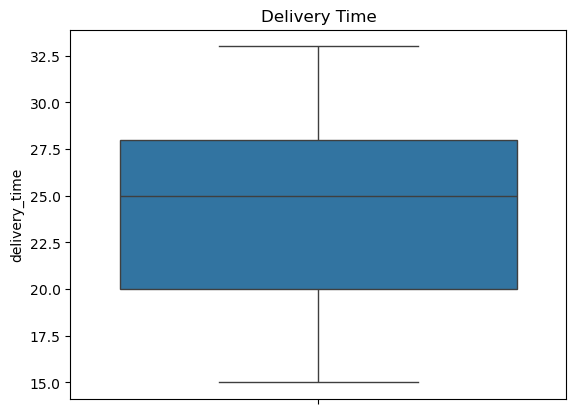

In [52]:
#boxplot for delivery time
sns.boxplot(data=df['delivery_time']);
plt.title('Delivery Time');

In [53]:
IQR(df['delivery_time'])

IQR: 8.0
Q1: 20.0
Q3: 28.0
upper bound: 40.0
lower bound: 8.0


In [54]:
df['delivery_time'].min()

15

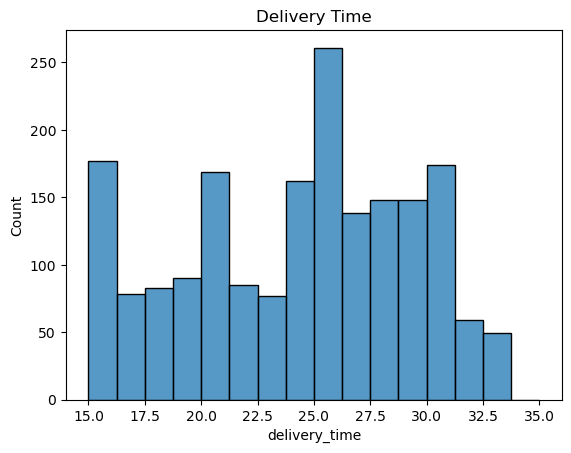

In [55]:
#Histogram of Delivery Time
sns.histplot(data=df['delivery_time'], binrange=[15,35]);
plt.title('Delivery Time');

#### Observations:
Below are the univariate analysis for the columns I thought it could apply towards. Ones left out include order_id, and customer_id:

Restaurant Name: Using the names of the restaurants, I counted how many times orders came from repeat restaurants. What I discovered is that the majority of orders are being placed with the same 21 restaurants. There are a total of 178 restaurants delivering food. The top 5 being Shake Shack (219), The Meatball Shop (132), Blue Ribbon Sushi (119), Blue Ribbon Fried Chicken (96), and Parm (68). 157 restaurants delivered less than 20 meals. When analyzing the data this way, there is a major right scew due to high volume from these 21 restaurants.

Cuisine Type: Using a histogram to analyze frequency of cuisine type orders, it is clear that 4 cuisines make up the majority of orders. These being American (30.8%), Japanese (24.8%), Italian (15.7%), and Chinese (11.3%). There are 11 other cuisines with a total of 15 cuisine choices for customers to choose from.

Cost of the Order: The majority of orders cost between 12.08 and 22.29 dollars (Q1:Q3). Whiskers from the boxplot show a right scew being influenced by expensive orders, the most expensive being $35.4 dollars. There are no outliers in the data.

Day_of_the_Week: The majority of orders are placed on the Weekend (71.18%) vs weekday which is (28.81%)

Rating: No one gave 1 or 2 star ratings. Rating were 59.11% 4 star, 30.97% 5 star, and 9.09% 3 star. The reason for the high amount of 4 star ratings is due to users not leaving a review and that being the imputed value from the previous question in this notebook. I feel that if users choose not to leave a review, they were most likely satisfied with their meal. Because of this I do think a 4 star rating is adequate.

Food Prep Time: The majority (25%/Q1) of orders happen within 23 minutes. the (Q3/75%) take 31 minutes. More orders are delivered quickly vs late. This is seen through the KDE line through the Histogram.

Delivery Time: The majority of orders take 20-28 minutes to deliver (Q1-Q3). Very rarely are deliveries late. Delivery time has a left scew being caused by excessively early deliveries.

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   order_id               1898 non-null   int64   
 1   customer_id            1898 non-null   int64   
 2   restaurant_name        1898 non-null   object  
 3   cuisine_type           1898 non-null   object  
 4   cost_of_the_order      1898 non-null   float64 
 5   day_of_the_week        1898 non-null   object  
 6   rating                 1898 non-null   category
 7   food_preparation_time  1898 non-null   int64   
 8   delivery_time          1898 non-null   int64   
dtypes: category(1), float64(1), int64(4), object(3)
memory usage: 120.7+ KB


### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [57]:
top_restaurant = df['restaurant_name'].value_counts().head(5)
print(top_restaurant)

restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
Name: count, dtype: int64


#### Observations:
The top 5 resturants in order from top to bottom are Shake Shack, The Meatball Shop, Blue Ribbon Sushi, Blue Ribbon Fried Chicken, and Parm.

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

<Axes: xlabel='day_of_the_week', ylabel='cuisine_type'>

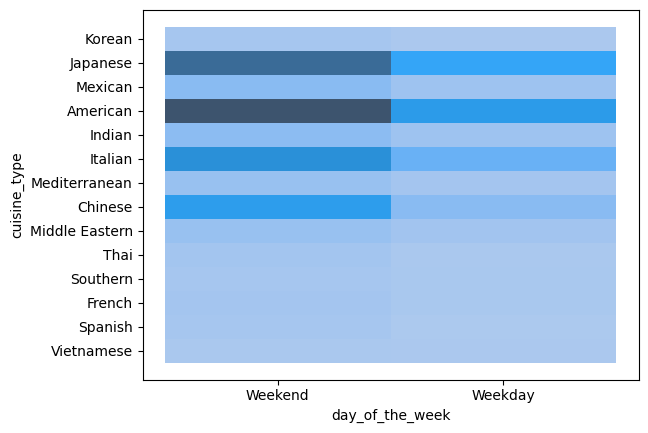

In [58]:
#Bivariate analysis comparing Day of the week orders and cusine type
sns.histplot(data=df,x=df['day_of_the_week'], y=df['cuisine_type'])

#### Observations:
The top cuisine on weekends is American food

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [59]:
# Write the code here
order_g_20 = df['cost_of_the_order'] > 20.0

#sum up all values greater than 20
count= 0
for i in order_g_20:
  if i == True:
    count += 1
#print(count)

#find total number of orders
total = df.shape[0]
#print(total)

#find the percent value
answer=count/total * 100
answer

print('The percent of orders more than 20 dollars is', answer, '%')




The percent of orders more than 20 dollars is 29.24130663856691 %


#### Observations:
The percent of orders that cost more than 20 dollars is 29.24%


### **Question 10**: What is the mean order delivery time? [1 mark]

In [60]:
#find the mean delivery time
df['delivery_time'].mean()

np.float64(24.161749209694417)

In [61]:
#double check based on IQR data
IQR(df['delivery_time'])

IQR: 8.0
Q1: 20.0
Q3: 28.0
upper bound: 40.0
lower bound: 8.0


#### Observations:
The mean order delivery time is 24.16 minutes.

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [62]:
# create variable that finds the top 3 most common occuring ID numbers.
top_customers = df['customer_id'].value_counts().head(3);
print(top_customers);

customer_id
52832    13
47440    10
83287     9
Name: count, dtype: int64


#### Observations:
The top 3 most frequent customers were 52832 with 13 orders, then 47440 with 10 orders, and 83287 with 9 orders.

### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


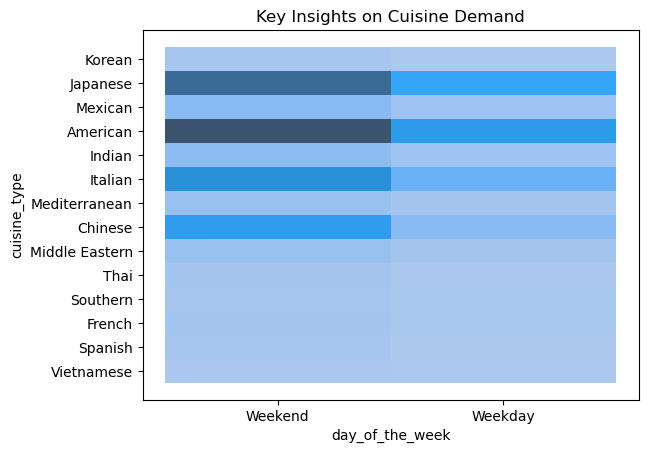

In [63]:
#Bivariate analysis comparing Day of the week orders and cuisine type
sns.histplot(data=df,x=df['day_of_the_week'], y=df['cuisine_type']);
plt.title('Key Insights on Cuisine Demand');

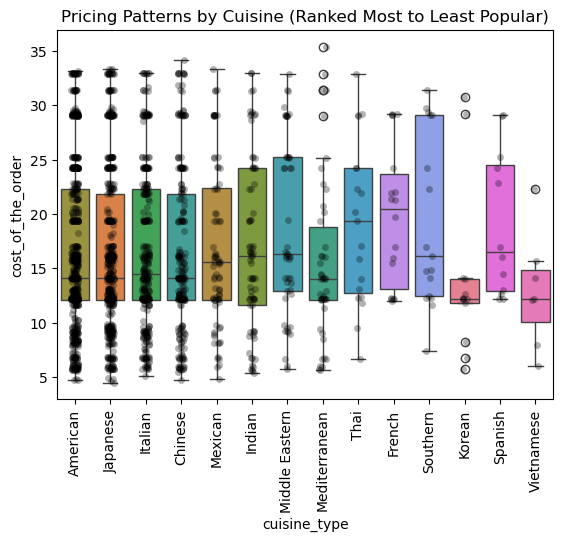

In [64]:
#Rank cuisines by most to least popular
popularity_order = df['cuisine_type'].value_counts().index;

sns.boxplot(data=df, x='cuisine_type', y='cost_of_the_order', order=popularity_order, hue='cuisine_type', legend=False);
sns.stripplot(data=df, x='cuisine_type', y='cost_of_the_order', order=popularity_order, color='black', alpha=0.3);
plt.xticks(rotation=90);
plt.title('Pricing Patterns by Cuisine (Ranked Most to Least Popular)');

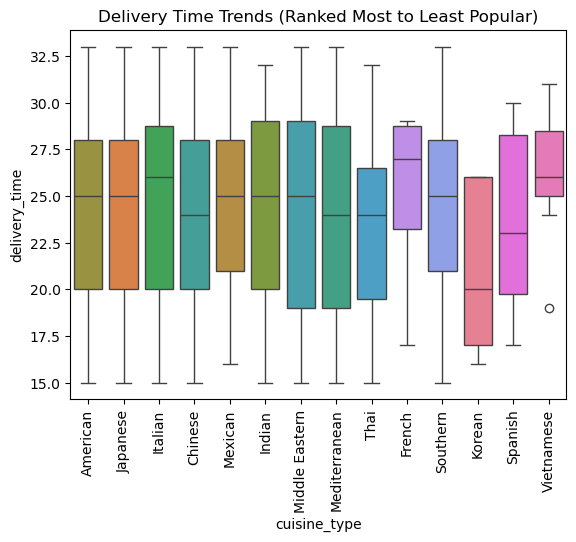

In [65]:
sns.boxplot(data=df, x='cuisine_type', y = 'delivery_time', order=popularity_order, hue='cuisine_type', legend=False);
plt.xticks(rotation=90);
plt.title('Delivery Time Trends (Ranked Most to Least Popular)');

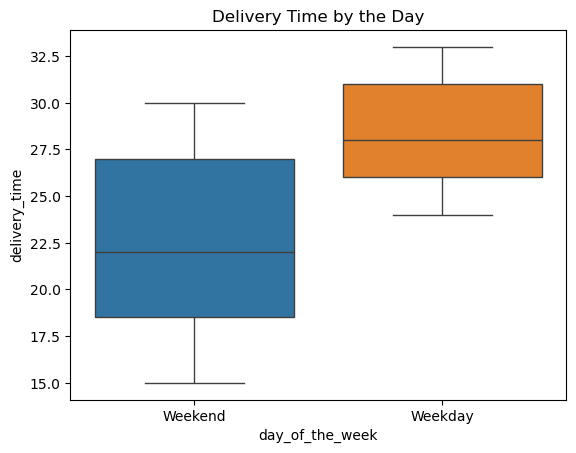

In [66]:
sns.boxplot(data=df, x='day_of_the_week', y='delivery_time', hue='day_of_the_week', legend=False);
plt.title('Delivery Time by the Day');

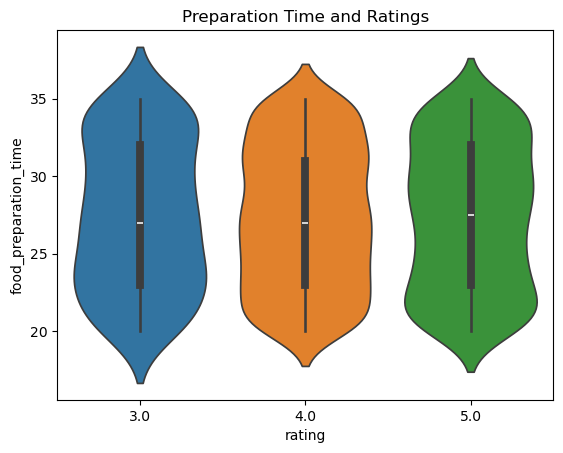

In [67]:
sns.violinplot(data=df, x=df['rating'], y=df['food_preparation_time'], hue='rating', legend=False);
plt.title('Preparation Time and Ratings');

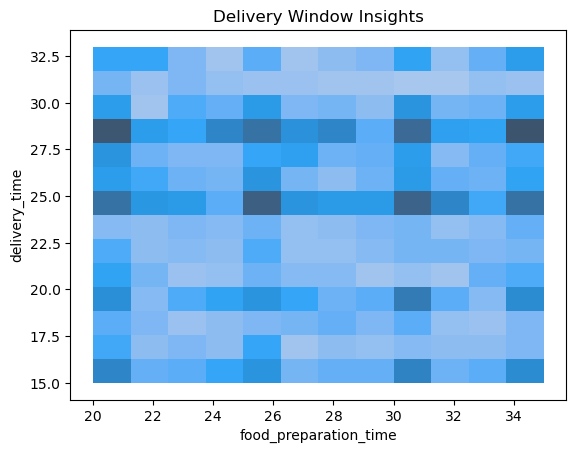

In [68]:
sns.histplot(data=df, x='food_preparation_time', y='delivery_time');
plt.title('Delivery Window Insights');

#### Observations:

Key Insights on Cuisine Demand

When analyzing order count by cuisine type, filtered by whether orders were placed on weekdays or weekends, a clear trend emerges: every cuisine receives more orders on weekends than on weekdays, based on the histplot.

Pricing Patterns by Cuisine

Niche restaurants show greater variability in order prices, with more extreme outliers compared to the top five most popular cuisines. In contrast, popular cuisines tend to have more predictable pricing. Although outliers for the top five cuisines cluster together, this may be due to higher order volumes. Tighter clusters could indicate menu items intended for individual consumption, while more evenly spread prices may suggest items better suited for sharing. This pattern is visible in American, Japanese, and Chinese cuisines. Less popular restaurants may be serving fewer people overall.

In addition, the top 3 restaurants (American, Japanese, Italian) have a clear trend of having lower cost options for customers. At the same time it is also clear that prices can be more expensive when ordering for multiple people.

Delivery Time Trends

More niche cuisines, such as French and Vietnamese, tend to have longer delivery times compared to others. Delivery times are generally shorter on weekends than on weekdays. This may be due to a higher number of delivery drivers working on weekends, possibly because some drivers work part-time and hold full-time jobs during the week.

Preparation Time and Ratings

When comparing food preparation time with customer ratings, there appears to be little to no correlation, and no clear patterns were identified.

Delivery Window Insights

Examining food preparation time alongside delivery time suggests that FoodHubs ideal total delivery window, from order placement through preparation to final delivery, is around 45 to 60 minutes. Outside of this range, customers may be less willing to wait. It is possible that FoodHub assigns drivers using historical data to meet these target timeframes.

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [69]:
#All restaurants have rating counts of more than 50 after my imputation of the rating 4. Next step would be the AVERAGE RATING NEEDS TO BE GREATER THAN 4

df['rating'] = df['rating'].astype(float)

# create restaurant/rating dataframe
restaurant_rating = df.groupby('restaurant_name')['rating']

#apply aggregate operations count of orders and mean rating
rest_rating_agg = restaurant_rating.agg(['count','mean'])

#apply requirements to qualify for the promotion.
qualified_restaurants_promo = rest_rating_agg[(rest_rating_agg['count'] > 50) & (rest_rating_agg['mean'] > 4.0)]

print(qualified_restaurants_promo)



                           count      mean
restaurant_name                           
Blue Ribbon Fried Chicken     96  4.218750
Blue Ribbon Sushi            119  4.134454
Parm                          68  4.073529
RedFarm Broadway              59  4.169492
RedFarm Hudson                55  4.109091
Shake Shack                  219  4.168950
The Meatball Shop            132  4.325758


#### Observations:
The restaurants that qualify for the promo are Blue Ribbon Fried Chicken, Blue Ribbon Sushi, Parm, Redfarm Broadway, Redfarm Hudson, Shake Shack, and the Meatball shop. This answer could have been influenced by the imputation. I decided not to revert my data.

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [70]:
#apply perameters to sort orders over $20
orders = df['cost_of_the_order']

#Create two dataframes one with values over 20 and the other with values > 5 < 20
over20 = orders[orders > 20]
less_than20 = orders[orders < 20]
over_5 = less_than20[less_than20 > 5]

#sum up over 20 values and add 25% charge
sum1 = over20.sum() * 1.25

#sum up over 5 values and add 15% charge
sum2 = over_5.sum() * 1.15

#find total revenue generated across all orders
revenue = sum1 + sum2
revenue = round(revenue,2)
print('Total revenue comes out too: $',revenue)

Total revenue comes out too: $ 37438.38


#### Observations:
Total Revenue plus the order charges comes out too 37438.38

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [71]:
#isolate delivery time
delivery_time = df['delivery_time'] + df['food_preparation_time']

#delivery time taking more than 60 minutes
more_than_60 = delivery_time[delivery_time > 60].count()
print(more_than_60)

#number of deliveries
total = delivery_time.count()

#finds the percent of orders
percent_over_60 = more_than_60 / total * 100

print('The percent of orders that take more than 60 Minutes',round(percent_over_60,2), '%')



200
The percent of orders that take more than 60 Minutes 10.54 %


#### Observations:
The percent of orders that take more than 60 minutes is 10.54%

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [72]:
data = df.groupby('day_of_the_week').delivery_time.agg('mean')

print('The mean delivery time during the Weekday is',round(data.iloc[0],2),'minutes')
print('The mean delivery time during the Weekend is',round(data.iloc[1],2), 'minutes')



The mean delivery time during the Weekday is 28.34 minutes
The mean delivery time during the Weekend is 22.47 minutes


#### Observations:
The mean delivery time on Weekday's is 28.34 minutes and on Weekend's it is 22.47 minutes.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
*  The analysis reveals clear patterns in customer demand, pricing behavior, and operational performance. In general more orders are being placed on Weekends vs the Weekday. and the majority of orders are being made for American, Japanese, Italian, and Chinese cuisines. Orders are being placed with mostly the same small group of restaurants, with just 21 out of 178 restaurants generating the majority of the platforms activity.

Prices tend to be less per dish with popular cusines, likely being influenced by the food being inexpensive and easy to share. It is also apparent that there is a strong niche of restaurants that recieve less demand but have pricier food options such as vietnamese, and French food.

From an Operational standpoint, Foodhub is extremely reliable when it comes to delivery times. With only 10.54% of deliveries taking more than 60 minutes. The majority of orders are being prepared + delivered in 45-60 minute time window. This could also contribute to why there are no 1-3 star ratings. I found this very odd, more research should go into why low rating reviews are not being recieved in this size dataset.

Overall, Foodhub is generating the majority of its revenue from the top 5 most popular cuisines. their delivery times are extremely reliable, niche restaurants are an area to grow demand during the weekday due ideal marketing conditions, and there are clear areas for improvement and operational efficiency.

### Recommendations:

*  Reduce additional fees during weekday delivery to incentize customers to order food during the slower days of the week.

* Promote Niche restaurants during the week given that it's likely 1-2 person orders are their strength vs on weekends promoting top cuisines and family/group order options with restaurant providers.

* There is a large amount of restaurants of Foodhub that don't recieve orders yet work with the service. Diving deeper into why these restaurants don't recieve orders is imperitive. I feel the likely solution is to promote less frequented restaurants on weekdays when customers are likely to be coming home from work and don't want to cook a meal. Incentizing regular customers with promotions to feed with these restaurants could build up their reputation and bring in more business for Foodhub and their supporting restaurants.

* On the Foodhub app, their front end team should be filtering the top 5 categories so they are easy to find.

---